# Author-level GPU access and productivity

The capacity notebook asked how unequally *works* are equipped. This asks the
same of *people*, then whether an author's output changes after a discrete jump
in the accelerator capacity they report.

> **Identification.** Access is chosen, not assigned. Nothing here is a causal
> effect. The estimand is: *how do trajectories change around a capacity jump,
> relative to matched peers who had not yet jumped?* Anticipation — the A100
> arrives *because* a big project is starting — inflates the estimate and leaves
> no pre-trend signature, so the pre-trend plot is a necessary but not sufficient
> diagnostic. Read it alongside the placebo, the `dc_first` event (procurement-
> driven, less anticipatory), and the coauthor-sourced split.

> **Measurement bias, both directions.** Semantic Scholar author-id *splits*
> truncate careers; a split at the jump year reads as an output drop and
> attenuates any post-jump effect. *Merges* inflate output and can fabricate
> jumps. Nothing fixes splits; the `>50 papers/year` screen is a crude merge
> filter and its bite is reported below.

**Kernel:** Python (accelscan); launch from a shell with `set -a; source .env; set +a`.

**Inputs** — run stage 4b first (`slurm/s2_authorship.txt`):

```bash
python -m accelscan.authorship --step crosswalk       # -> .../authorship/{release}/crosswalk/parts
python -m accelscan.authorship --step panel           # -> .../analytic/{rv}/p1/qwen3-14b/authors/
python -m accelscan.authorship --step panel --count-policy explicit
```


In [1]:
import os
# the other five notebooks carry this guard too: every path here is
# repo-relative (registry/hardware.yaml, output/analysis/), and nbconvert
# runs the kernel in the notebook's own directory
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

%matplotlib inline
# The analysis helpers live in accelscan.authorship and are edited while this
# notebook is open. Without autoreload a live kernel keeps the module it first
# imported, and an added function shows up as an AttributeError -- with the
# panel (minutes to load from S3) held hostage to a kernel restart.
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from accelscan import authorship as au
from accelscan.config import BUCKET
from accelscan.paths import S2ORC, author_analytic_key
from accelscan.plotting import setup_figures
from accelscan.registry import load_registry
from accelscan.s3 import storage_options

# integer year ticks + every figure exported to output/analysis/authors/
setup_figures('authors')

## Knobs

In [2]:
COUNT_POLICY = 'floor1'      # 'floor1' (primary) | 'explicit' (robustness)
MODEL_TAG, PROMPT_VERSION = 'qwen3-14b', 'p1'
YEAR_MIN, YEAR_MAX = 2005, 2025
EVENT_TYPE = 'ratio_jump'    # primary event; 'dc_first' / 'gpu_first' secondary
MIN_AUTHORS_PER_YEAR = 50    # suppress year points with too little support
TOP_FIELDS = 8
LOCAL_PANEL = None           # e.g. 'output/authors_smoke' to read a local dev run

C_MED, C_P90, C_FRONT = '#0072B2', '#56B4E9', '#D55E00'
C_RISK, C_NEVER = '#0072B2', '#D55E00'
reg = load_registry()
so = storage_options()

## Load the author-year panel and the jumps table

In [3]:
def load(name, policy=COUNT_POLICY):
    if LOCAL_PANEL:
        return pl.read_parquet(f'{LOCAL_PANEL}/{name}_{policy}.parquet')
    key = author_analytic_key(S2ORC, reg.version, PROMPT_VERSION, MODEL_TAG,
                              f'{name}_{policy}')
    return pl.read_parquet(f's3://{BUCKET}/{key}', storage_options=so)

panel = au.add_outcomes(load('author_year').filter(
    pl.col('year').is_between(YEAR_MIN, YEAR_MAX)))
# The jumps table is built on the unfiltered panel, so restrict it to the same
# year window as the panel -- an event outside it has no tau data to study.
jumps = load('author_jumps').filter(
    pl.col('event_year').is_between(YEAR_MIN, YEAR_MAX))

gpu = panel.filter(pl.col('control_sample') == 'gpu_ever')
print(f'{panel.height:,} author-years | {panel["authorid"].n_unique():,} authors '
      f'({gpu["authorid"].n_unique():,} GPU-ever, '
      f'{panel.filter(pl.col("control_sample") == "never_gpu")["authorid"].n_unique():,} '
      f'never-GPU controls)')
print(jumps.group_by('event_type').agg(n=pl.len()).sort('n', descending=True))

16,167,380 author-years | 1,422,501 authors (507,463 GPU-ever, 915,038 never-GPU controls)
shape: (3, 2)
┌────────────┬────────┐
│ event_type ┆ n      │
│ ---        ┆ ---    │
│ str        ┆ u32    │
╞════════════╪════════╡
│ gpu_first  ┆ 496653 │
│ dc_first   ┆ 155440 │
│ ratio_jump ┆ 30239  │
└────────────┴────────┘


## Population sanity, and what the filters removed

The `>50 papers/year` screen is a merged-profile heuristic, not a substantive
choice, so its bite has to be visible before anything downstream is believed.

shape: (1, 6)
┌───────────┬────────────┬────────────┬────────────┬──────────┬───────────────┐
│ n_authors ┆ papers_p50 ┆ papers_p90 ┆ papers_p99 ┆ span_p50 ┆ peak_year_p99 │
│ ---       ┆ ---        ┆ ---        ┆ ---        ┆ ---      ┆ ---           │
│ u32       ┆ f64        ┆ f64        ┆ f64        ┆ f64      ┆ f64           │
╞═══════════╪════════════╪════════════╪════════════╪══════════╪═══════════════╡
│ 1422501   ┆ 9.0        ┆ 63.0       ┆ 282.0      ┆ 12.0     ┆ 32.0          │
└───────────┴────────────┴────────────┴────────────┴──────────┴───────────────┘
authors at the 50-papers/year screen boundary: 527


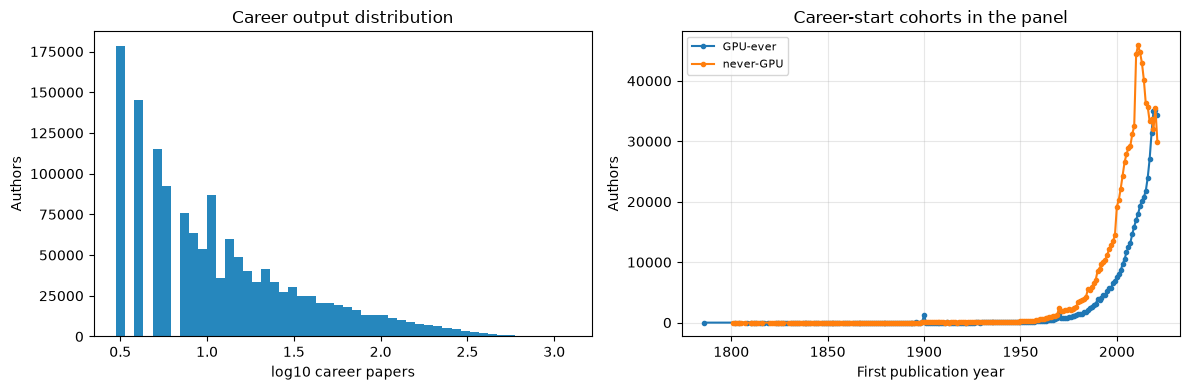

In [4]:
per_author = panel.group_by('authorid').agg(
    pl.first('n_career_papers'), pl.first('y0'), pl.first('y1'),
    pl.first('modal_field'), pl.first('ever_gpu'), pl.first('control_sample'),
    peak_year_papers=pl.col('n_papers').max(),
    n_accel_career=pl.col('n_accel').sum())
print(per_author.select(
    n_authors=pl.len(),
    papers_p50=pl.col('n_career_papers').median(),
    papers_p90=pl.col('n_career_papers').quantile(0.9),
    papers_p99=pl.col('n_career_papers').quantile(0.99),
    span_p50=(pl.col('y1') - pl.col('y0') + 1).median(),
    peak_year_p99=pl.col('peak_year_papers').quantile(0.99)))
print(f'authors at the {au.MAX_PAPERS_PER_YEAR}-papers/year screen boundary: '
      f'{per_author.filter(pl.col("peak_year_papers") == au.MAX_PAPERS_PER_YEAR).height:,}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log10(per_author['n_career_papers'].to_numpy()), bins=50,
             color=C_MED, alpha=0.85)
axes[0].set(xlabel='log10 career papers', ylabel='Authors',
            title='Career output distribution')
for lab, sub in (('GPU-ever', per_author.filter(pl.col('ever_gpu'))),
                 ('never-GPU', per_author.filter(~pl.col('ever_gpu')))):
    c = (sub.group_by('y0').agg(n=pl.len()).sort('y0'))
    axes[1].plot(c['y0'], c['n'], marker='o', ms=3, label=lab)
axes[1].set(xlabel='First publication year', ylabel='Authors',
            title='Career-start cohorts in the panel')
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Author-level inequality of reported access

The author analogue of §5's compute-concentration figures. The unit is the
author-year, and access is the **max reported FP32 over that author's
used-accelerator papers that year** (full-count attribution). Authors with no
reported access that year are absent from these figures, never zero — a Gini over
zero-filled non-users would measure adoption, not inequality among users.

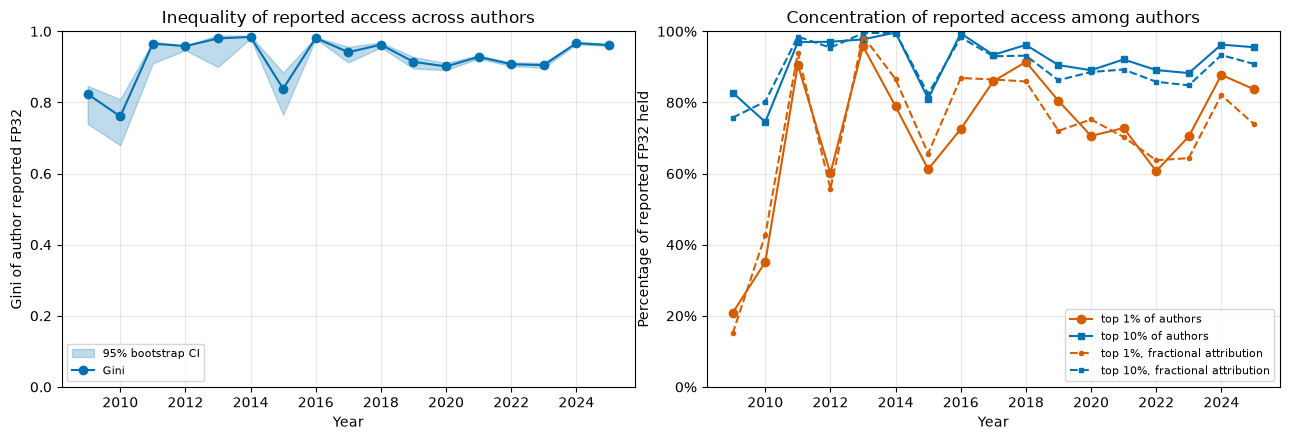

shape: (17, 12)
┌──────┬───────┬───────┬──────────┬───┬──────────────┬───────────────┬──────────┬───────────┐
│ year ┆ n     ┆ gini  ┆ lo       ┆ … ┆ top1pct_frac ┆ top10pct_frac ┆ p50      ┆ p90       │
│ ---  ┆ ---   ┆ ---   ┆ ---      ┆   ┆ ---          ┆ ---           ┆ ---      ┆ ---       │
│ i64  ┆ i64   ┆ f64   ┆ f64      ┆   ┆ f64          ┆ f64           ┆ f64      ┆ f64       │
╞══════╪═══════╪═══════╪══════════╪═══╪══════════════╪═══════════════╪══════════╪═══════════╡
│ 2009 ┆ 187   ┆ 0.824 ┆ 0.739559 ┆ … ┆ 0.15         ┆ 0.757         ┆ 622.1    ┆ 3608.152  │
│ 2010 ┆ 464   ┆ 0.761 ┆ 0.67953  ┆ … ┆ 0.427        ┆ 0.802         ┆ 1030.0   ┆ 3083.48   │
│ 2011 ┆ 582   ┆ 0.965 ┆ 0.909992 ┆ … ┆ 0.939        ┆ 0.985         ┆ 1030.0   ┆ 4743.168  │
│ 2012 ┆ 882   ┆ 0.958 ┆ 0.946734 ┆ … ┆ 0.557        ┆ 0.954         ┆ 1088.64  ┆ 5380.0    │
│ 2013 ┆ 1283  ┆ 0.98  ┆ 0.899627 ┆ … ┆ 0.987        ┆ 0.995         ┆ 1581.056 ┆ 6354.0    │
│ 2014 ┆ 1574  ┆ 0.984 ┆ 0.980263 ┆ … ┆ 0.86

In [5]:
def gini(x: np.ndarray) -> float:
    x = np.sort(x[np.isfinite(x)])
    if x.size == 0 or x.sum() == 0:
        return float('nan')
    n = x.size
    return float((2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum()))

def lorenz(v: np.ndarray):
    v = np.sort(v[np.isfinite(v) & (v > 0)])
    cum = np.cumsum(v) / v.sum()
    return np.insert(np.arange(1, v.size + 1) / v.size, 0, 0), np.insert(cum, 0, 0)

acc = gpu.filter(pl.col('access_fp32_max').is_not_null())
rng = np.random.default_rng(42)
B = 300
rows = []
for y in sorted(acc['year'].unique().to_list()):
    v = acc.filter(pl.col('year') == y)['access_fp32_max'].to_numpy().astype(float)
    if v.size < MIN_AUTHORS_PER_YEAR:
        continue
    boots = [gini(rng.choice(v, v.size, replace=True)) for _ in range(B)]
    k = max(1, int(round(0.01 * v.size)))
    k10 = max(1, int(round(0.10 * v.size)))
    sv = np.sort(v)
    # Two concentration measures, because they answer different questions. The
    # max-based one matches the Gini/Lorenz above (share of the access
    # distribution). The fractional one -- each paper's capacity split across its
    # authors -- is the "does 1% of GPU-using authors command 90% of reported
    # FLOPS?" quantity, and avoids crediting a shared cluster to every coauthor
    # in full. Restricted to author-years with reported access, so an author with
    # no spec'd access does not enter as a zero.
    f = (acc.filter(pl.col('year') == y)['access_frac_sum']
         .to_numpy().astype(float))
    fs = np.sort(f[np.isfinite(f)])
    fk, fk10 = max(1, int(round(0.01 * fs.size))), max(1, int(round(0.10 * fs.size)))
    rows.append({'year': y, 'n': v.size, 'gini': gini(v),
                 'lo': float(np.nanpercentile(boots, 2.5)),
                 'hi': float(np.nanpercentile(boots, 97.5)),
                 'top1pct': float(sv[-k:].sum() / v.sum()),
                 'top10pct': float(sv[-k10:].sum() / v.sum()),
                 'gini_frac': gini(fs),
                 'top1pct_frac': float(fs[-fk:].sum() / fs.sum()) if fs.sum() else float('nan'),
                 'top10pct_frac': float(fs[-fk10:].sum() / fs.sum()) if fs.sum() else float('nan'),
                 'p50': float(np.median(v)), 'p90': float(np.quantile(v, 0.9))})
conc = pl.DataFrame(rows).sort('year')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].fill_between(conc['year'], conc['lo'], conc['hi'], color=C_MED, alpha=0.25,
                     label='95% bootstrap CI')
axes[0].plot(conc['year'], conc['gini'], marker='o', color=C_MED, label='Gini')
axes[0].set(xlabel='Year', ylabel='Gini of author reported FP32', ylim=(0, 1),
            title='Inequality of reported access across authors')
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[1].plot(conc['year'], 100 * conc['top1pct'], marker='o', color=C_FRONT,
             label='top 1% of authors')
axes[1].plot(conc['year'], 100 * conc['top10pct'], marker='s', ms=4, color=C_MED,
             label='top 10% of authors')
axes[1].plot(conc['year'], 100 * conc['top1pct_frac'], marker='o', ms=3,
             color=C_FRONT, ls='--', label='top 1%, fractional attribution')
axes[1].plot(conc['year'], 100 * conc['top10pct_frac'], marker='s', ms=3,
             color=C_MED, ls='--', label='top 10%, fractional attribution')
axes[1].set(xlabel='Year', ylabel='Percentage of reported FP32 held', ylim=(0, 100),
            title='Concentration of reported access among authors')
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
with pl.Config(tbl_rows=25):
    print(conc.with_columns(pl.col('gini').round(3), pl.col('top1pct').round(3),
                           pl.col('top10pct').round(3), pl.col('gini_frac').round(3),
                           pl.col('top1pct_frac').round(3),
                           pl.col('top10pct_frac').round(3)))

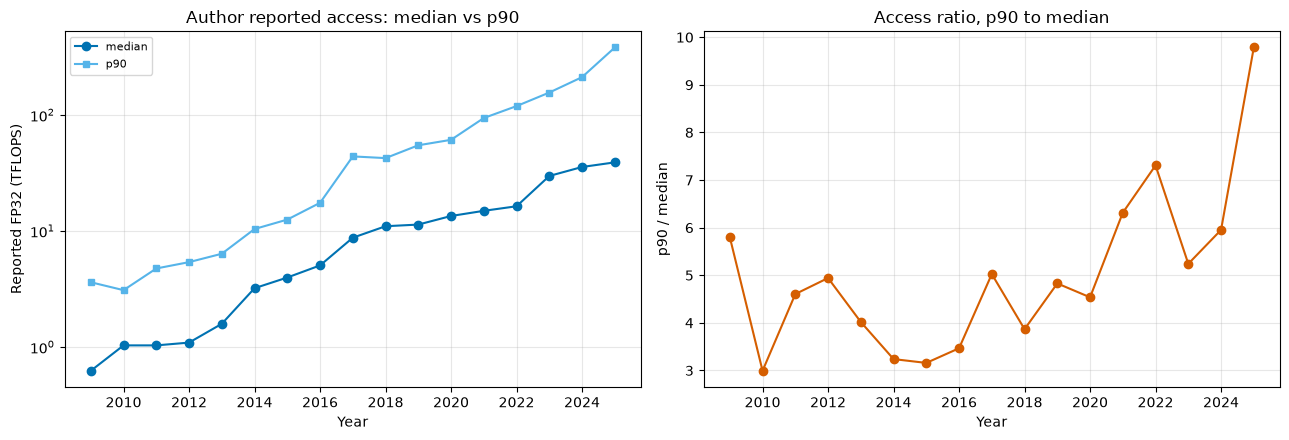

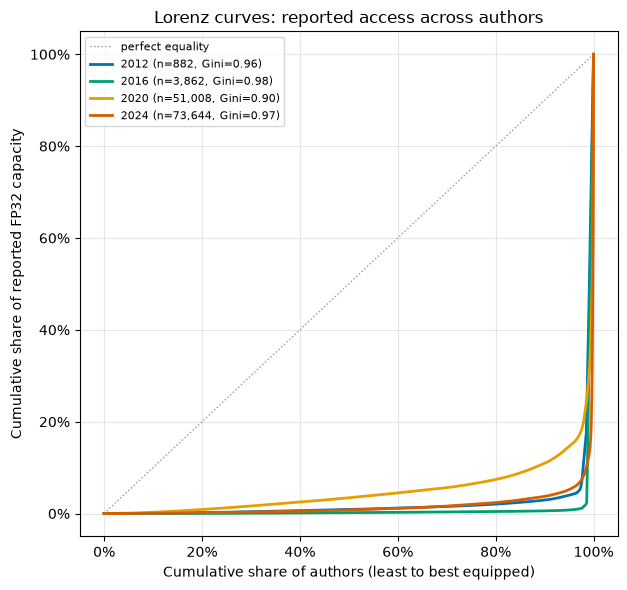

In [6]:
# p90-vs-median author access, the direct analogue of the paper-level figure
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(conc['year'], conc['p50'] / 1000, marker='o', color=C_MED, label='median')
axes[0].plot(conc['year'], conc['p90'] / 1000, marker='s', ms=4, color=C_P90, label='p90')
axes[0].set(xlabel='Year', ylabel='Reported FP32 (TFLOPS)', yscale='log',
            title='Author reported access: median vs p90')
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[1].plot(conc['year'], conc['p90'] / conc['p50'], marker='o', color=C_FRONT)
axes[1].set(xlabel='Year', ylabel='p90 / median', title='Access ratio, p90 to median')
axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Lorenz curves at benchmark years
BENCH = [y for y in (2012, 2016, 2020, 2024)
         if acc.filter(pl.col('year') == y).height >= 100]
fig, ax = plt.subplots(figsize=(6.2, 6))
ax.plot([0, 1], [0, 1], color='#999999', lw=1, ls=':', label='perfect equality')
for y, c in zip(BENCH, ['#0072B2', '#009E73', '#E69F00', '#D55E00']):
    v = acc.filter(pl.col('year') == y)['access_fp32_max'].to_numpy().astype(float)
    x, cum = lorenz(v)
    ax.plot(x, cum, color=c, lw=2, label=f'{y} (n={v.size:,}, Gini={gini(v):.2f})')
ax.set(xlabel='Cumulative share of authors (least to best equipped)',
       ylabel='Cumulative share of reported FP32 capacity',
       title='Lorenz curves: reported access across authors')
ax.legend(fontsize=8, loc='upper left'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

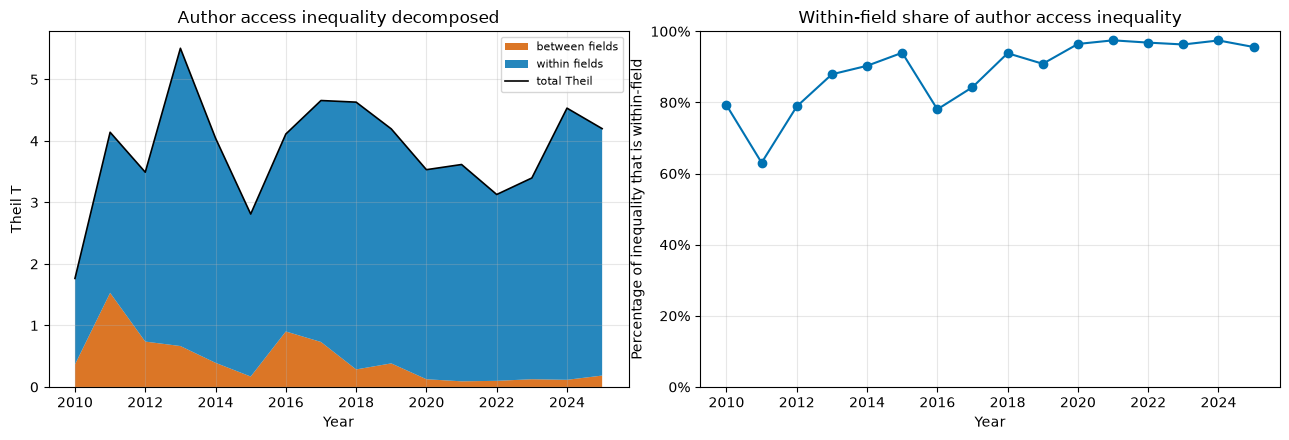

shape: (16, 6)
┌──────┬───────┬─────────────┬───────────────┬──────────────┬──────────────┐
│ year ┆ n     ┆ theil_total ┆ between_field ┆ within_field ┆ within_share │
│ ---  ┆ ---   ┆ ---         ┆ ---           ┆ ---          ┆ ---          │
│ i64  ┆ i64   ┆ f64         ┆ f64           ┆ f64          ┆ f64          │
╞══════╪═══════╪═════════════╪═══════════════╪══════════════╪══════════════╡
│ 2010 ┆ 464   ┆ 1.764       ┆ 0.366         ┆ 1.398        ┆ 0.792        │
│ 2011 ┆ 582   ┆ 4.141       ┆ 1.53          ┆ 2.611        ┆ 0.631        │
│ 2012 ┆ 882   ┆ 3.491       ┆ 0.737         ┆ 2.754        ┆ 0.789        │
│ 2013 ┆ 1283  ┆ 5.506       ┆ 0.665         ┆ 4.841        ┆ 0.879        │
│ 2014 ┆ 1574  ┆ 4.045       ┆ 0.392         ┆ 3.653        ┆ 0.903        │
│ 2015 ┆ 2002  ┆ 2.811       ┆ 0.169         ┆ 2.642        ┆ 0.94         │
│ 2016 ┆ 3862  ┆ 4.112       ┆ 0.902         ┆ 3.21         ┆ 0.781        │
│ 2017 ┆ 8383  ┆ 4.656       ┆ 0.731         ┆ 3.925        ┆

In [7]:
# Theil decomposition: is the author-level compute divide between or within fields?
def theil(v: np.ndarray) -> float:
    v = v[np.isfinite(v) & (v > 0)]
    if v.size == 0:
        return float('nan')
    mu = v.mean()
    return float(np.mean((v / mu) * np.log(v / mu)))

rows = []
for y in sorted(acc['year'].unique().to_list()):
    sub = acc.filter((pl.col('year') == y) & pl.col('modal_field').is_not_null()
                     & (pl.col('access_fp32_max') > 0))
    v = sub['access_fp32_max'].to_numpy().astype(float)
    if v.size < 200:
        continue
    total, mu = theil(v), v.mean()
    between = within = 0.0
    for (f,), g in sub.group_by('modal_field'):
        gv = g['access_fp32_max'].to_numpy().astype(float)
        s = gv.sum() / v.sum()
        if gv.size == 0 or gv.mean() <= 0:
            continue
        between += s * np.log(gv.mean() / mu)
        within += s * theil(gv)
    rows.append({'year': y, 'n': v.size, 'theil_total': total,
                 'between_field': between, 'within_field': within,
                 'within_share': within / total if total else float('nan')})
th = pl.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].stackplot(th['year'], th['between_field'], th['within_field'],
                  labels=['between fields', 'within fields'],
                  colors=['#D55E00', '#0072B2'], alpha=0.85)
axes[0].plot(th['year'], th['theil_total'], color='black', lw=1.2, label='total Theil')
axes[0].set(xlabel='Year', ylabel='Theil T',
            title='Author access inequality decomposed')
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[1].plot(th['year'], 100 * th['within_share'], marker='o', color=C_MED)
axes[1].set(xlabel='Year', ylabel='Percentage of inequality that is within-field',
            ylim=(0, 100), title='Within-field share of author access inequality')
axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
with pl.Config(tbl_rows=25):
    print(th.with_columns(pl.col('theil_total').round(3),
                          pl.col('between_field').round(3),
                          pl.col('within_field').round(3),
                          pl.col('within_share').round(3)))

### Access mobility

Is the access hierarchy sticky? Quintiles are cut **within year** on the access
stock, so this is relative position, not absolute capacity (which rises for
everyone).

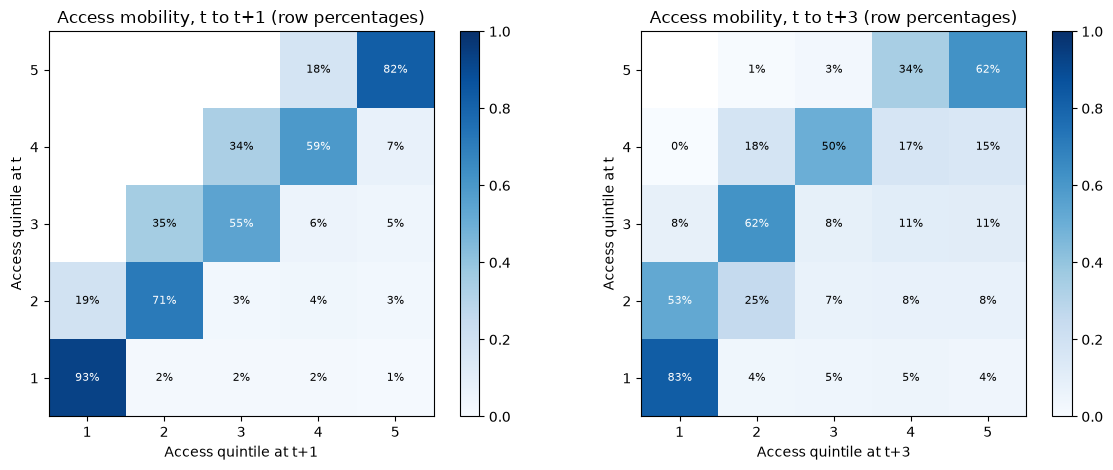

In [8]:
st = gpu.filter(pl.col('access_fp32_stock').is_not_null()).select(
    'authorid', 'year', 'access_fp32_stock')
st = st.with_columns(
    q=(pl.col('access_fp32_stock').rank('ordinal').over('year')
       / pl.len().over('year') * 5).ceil().clip(1, 5).cast(pl.Int32))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, lag in zip(axes, (1, 3)):
    nxt = st.select('authorid', q_next='q',
                    year=pl.col('year').cast(pl.Int32) - lag).with_columns(
                        pl.col('year').cast(st.schema['year']))
    tr = st.join(nxt, on=['authorid', 'year'], how='inner')
    m = np.full((5, 5), np.nan)
    for (a, b), g in tr.group_by(['q', 'q_next']):
        m[a - 1, b - 1] = g.height
    m = m / np.nansum(m, axis=1, keepdims=True)
    im = ax.imshow(m, cmap='Blues', vmin=0, vmax=1, origin='lower')
    for i in range(5):
        for j in range(5):
            if np.isfinite(m[i, j]):
                ax.text(j, i, f'{100*m[i, j]:.0f}%', ha='center', va='center',
                        fontsize=8, color='white' if m[i, j] > 0.5 else 'black')
    ax.set(xticks=range(5), yticks=range(5),
           xticklabels=range(1, 6), yticklabels=range(1, 6),
           xlabel=f'Access quintile at t+{lag}', ylabel='Access quintile at t',
           title=f'Access mobility, t to t+{lag} (row percentages)')
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

## Jumps: what the events look like

`ratio_jump` (primary) is the first year an author's reported FP32 is at least
`JUMP_RATIO`x their prior career max — a jump, not adoption, since it requires
prior access. `dc_first` is the consumer-to-datacenter crossing; `gpu_first` is
adoption.

ratio_jump: 30,239 authors, event years 2010-2025, median career year 9.0
dc_first: 155,440 authors, event years 2007-2025, median career year 9.0
gpu_first: 496,653 authors, event years 2005-2025, median career year 10.0


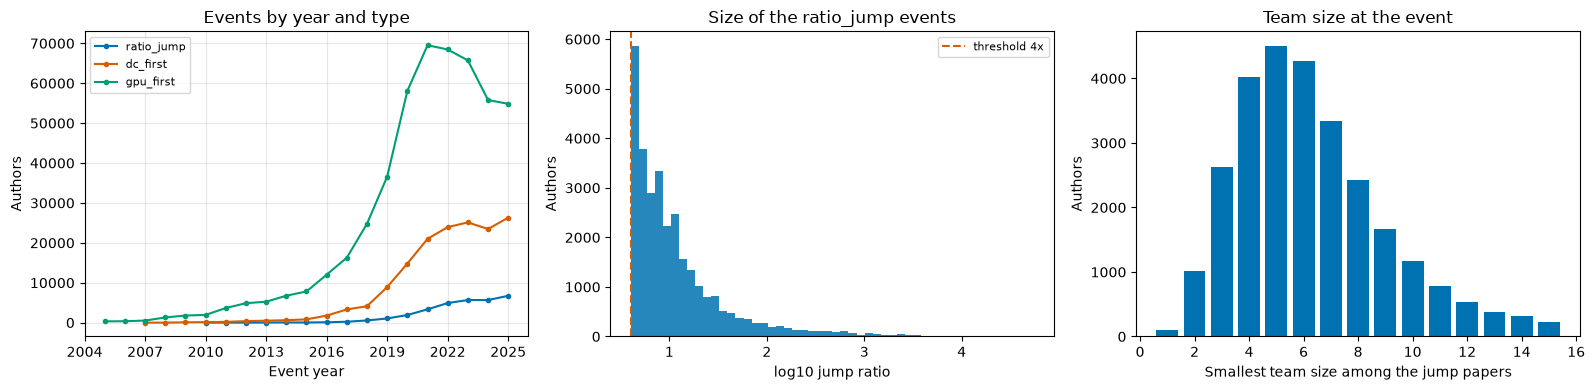

In [9]:
for et in au.EVENT_TYPES:
    j = jumps.filter(pl.col('event_type') == et)
    print(f'{et}: {j.height:,} authors, event years '
          f'{j["event_year"].min()}-{j["event_year"].max()}, '
          f'median career year {j["career_year_at_event"].median()}')

pj = jumps.filter(pl.col('event_type') == EVENT_TYPE)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for et, c in zip(au.EVENT_TYPES, [C_MED, C_FRONT, '#009E73']):
    k = (jumps.filter(pl.col('event_type') == et)
         .group_by('event_year').agg(n=pl.len()).sort('event_year'))
    axes[0].plot(k['event_year'], k['n'], marker='o', ms=3, label=et, color=c)
axes[0].set(xlabel='Event year', ylabel='Authors', title='Events by year and type')
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

r = pj['jump_ratio'].drop_nulls().to_numpy().astype(float)
axes[1].hist(np.log10(r), bins=50, color=C_MED, alpha=0.85)
axes[1].axvline(np.log10(au.JUMP_RATIO), color=C_FRONT, ls='--',
                label=f'threshold {au.JUMP_RATIO:g}x')
axes[1].set(xlabel='log10 jump ratio', ylabel='Authors',
            title=f'Size of the {EVENT_TYPE} events')
axes[1].legend(fontsize=8)

ts = (pj.group_by('min_team_size').agg(n=pl.len()).sort('min_team_size').head(15))
axes[2].bar(ts['min_team_size'], ts['n'], color=C_MED)
axes[2].set(xlabel='Smallest team size among the jump papers', ylabel='Authors',
            title='Team size at the event')
plt.tight_layout(); plt.show()

### Coauthor provenance of the jump

The obvious rival explanation is that the treatment is not the hardware but a
well-equipped collaborator. `coauthor_sourced` is true when some coauthor of a
jump paper already held at least half the jump's capacity in the prior year.
Every coauthor of an accelerator-using paper is in the panel by construction, so
this is an exact comparison, not a lower bound.

coauthor-sourced overall: 39.2% of 30,239 ratio_jump events
shape: (4, 3)
┌──────┬───────┬──────────┐
│ team ┆ n     ┆ sourced  │
│ ---  ┆ ---   ┆ ---      │
│ str  ┆ u32   ┆ f64      │
╞══════╪═══════╪══════════╡
│ 1-2  ┆ 1116  ┆ 0.103047 │
│ 11+  ┆ 5080  ┆ 0.564961 │
│ 3-5  ┆ 11162 ┆ 0.29036  │
│ 6-10 ┆ 12881 ┆ 0.437466 │
└──────┴───────┴──────────┘


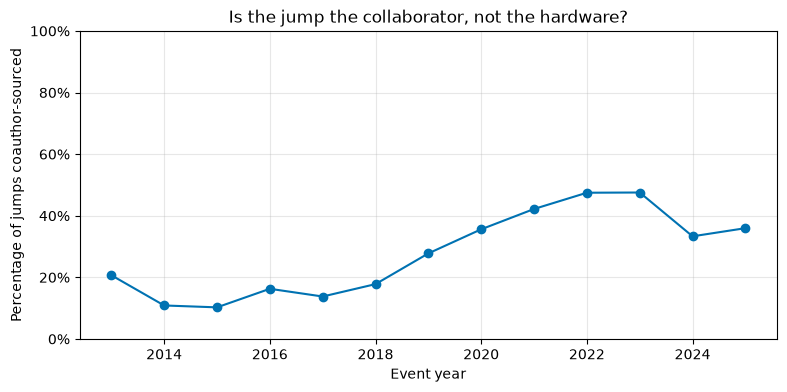

In [10]:
cs = (pj.group_by('event_year').agg(
        n=pl.len(), sourced=pl.col('coauthor_sourced').mean()).sort('event_year')
      .filter(pl.col('n') >= 20))
by_team = (pj.with_columns(team=pl.when(pl.col('min_team_size') <= 2).then(pl.lit('1-2'))
                          .when(pl.col('min_team_size') <= 5).then(pl.lit('3-5'))
                          .when(pl.col('min_team_size') <= 10).then(pl.lit('6-10'))
                          .otherwise(pl.lit('11+')))
           .group_by('team').agg(n=pl.len(), sourced=pl.col('coauthor_sourced').mean()))
print(f'coauthor-sourced overall: {100 * pj["coauthor_sourced"].mean():.1f}% '
      f'of {pj.height:,} {EVENT_TYPE} events')
print(by_team.sort('team'))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(cs['event_year'], 100 * cs['sourced'], marker='o', color=C_MED)
ax.set(xlabel='Event year', ylabel='Percentage of jumps coauthor-sourced',
       ylim=(0, 100), title='Is the jump the collaborator, not the hardware?')
ax.grid(alpha=0.3); plt.show()

## Event study

For each jumper, the outcome is demeaned against that author's own pre-period
mean over tau in `BASE_TAUS` (tau=-1 excluded, for anticipation), then the matched
controls' mean trend at the same tau is subtracted. CIs are a block bootstrap over
jumpers, since the jumper (with its controls) is the unit of independence.

Two control variants, both reported:

- **risk-set** — GPU-ever authors who have not yet jumped by the jumper's event
  year, matched on field x career-age bin x pre-period output quartile. The
  defensible comparison: everyone in it is on an accelerator-using trajectory.
- **plus never-GPU** — the same pool plus never-GPU authors from
  accelerator-active fields. Read as an **upper bound**: never-GPU authors differ
  from jumpers on everything, not just timing.

**Units.** Every outcome is a *count per year* — papers, accelerator papers,
citations per paper — so each y axis reads directly in those units and can be
negative (it is a change relative to the author's own baseline *and* to controls).
`log(1 + papers)` is reported once, beside the count, as a robustness scale only.
It cannot be the headline: θ on the log is a difference of mean logs, and
back-transforming it to a count via `(exp(θ) − 1) × (1 + baseline)` is merely an
approximation — on the full panel that gives +1.49 papers at τ=−1 where the same
event study run directly on the count gives +1.23. Both cost the same to compute,
so the exact one is what gets published.

> **tau=0 is mechanically contaminated**: the jump *is* a paper, so output there
> is >=1 by construction. Read tau>=1, and read `n_nonaccel` — output that does
> not itself involve an accelerator — as the least contaminated outcome.

ratio_jump/riskset: 25,917 of 30,239 jumpers matched, 129,564 pairs, 94,265 controls
ratio_jump/plus_never_gpu: 25,917 of 30,239 jumpers matched, 129,566 pairs, 103,058 controls


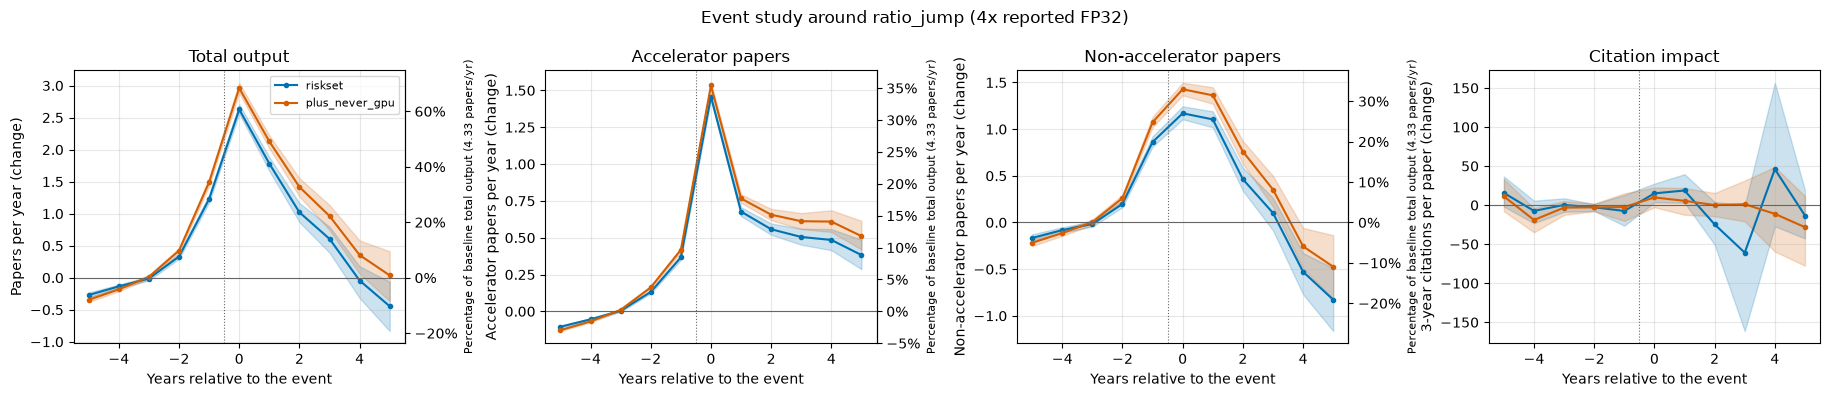

baseline output for these jumpers: 4.33 papers/year — every "_pct" column below is the effect as a percentage of that
--- n_papers (risk-set controls) ---
shape: (11, 8)
┌─────┬───────┬───────┬───────┬───────────┬────────┬────────┬───────┐
│ tau ┆ theta ┆ lo    ┆ hi    ┆ theta_pct ┆ lo_pct ┆ hi_pct ┆ n     │
│ --- ┆ ---   ┆ ---   ┆ ---   ┆ ---       ┆ ---    ┆ ---    ┆ ---   │
│ i64 ┆ f64   ┆ f64   ┆ f64   ┆ f64       ┆ f64    ┆ f64    ┆ i64   │
╞═════╪═══════╪═══════╪═══════╪═══════════╪════════╪════════╪═══════╡
│ -5  ┆ -0.27 ┆ -0.31 ┆ -0.23 ┆ -6.25     ┆ -7.06  ┆ -5.33  ┆ 22967 │
│ -4  ┆ -0.14 ┆ -0.17 ┆ -0.11 ┆ -3.14     ┆ -3.83  ┆ -2.45  ┆ 25917 │
│ -3  ┆ -0.01 ┆ -0.04 ┆ 0.02  ┆ -0.28     ┆ -0.99  ┆ 0.4    ┆ 25917 │
│ -2  ┆ 0.33  ┆ 0.29  ┆ 0.37  ┆ 7.62      ┆ 6.79   ┆ 8.51   ┆ 25917 │
│ -1  ┆ 1.23  ┆ 1.17  ┆ 1.29  ┆ 28.37     ┆ 27.12  ┆ 29.87  ┆ 25917 │
│ …   ┆ …     ┆ …     ┆ …     ┆ …         ┆ …      ┆ …      ┆ …     │
│ 1   ┆ 1.78  ┆ 1.67  ┆ 1.88  ┆ 41.16     ┆ 38.53  ┆ 43.44  

In [11]:
def run_event_study(event_type=EVENT_TYPE, outcomes=au.OUTCOMES,
                    variants=('riskset', 'plus_never_gpu'), jump_table=None,
                    panel_df=None, seed=au.SEED, b=au.BOOTSTRAP_B):
    p = panel if panel_df is None else panel_df
    j = (jump_table if jump_table is not None else jumps).filter(
        pl.col('event_type') == event_type)
    # carried alongside the results so every figure can show the percent-of-
    # baseline axis for its OWN jumpers, not a global average
    out = {'_baseline': float(j['pre_papers_mean'].mean())}
    for v in variants:
        ctrl = au.match_controls(p, j, variant=v, seed=seed)
        n_matched = ctrl['authorid'].n_unique()
        print(f'{event_type}/{v}: {n_matched:,} of {j.height:,} jumpers matched, '
              f'{ctrl.height:,} pairs, {ctrl["control_id"].n_unique():,} controls')
        for o in outcomes:
            out[(v, o)] = au.event_study(p, j, ctrl, o, b=b, seed=seed)
    return out

# Every count outcome is a change in papers per year, relative to the author's
# own pre-period AND to matched controls -- so the axis unit is papers, and it can
# legitimately be negative. `log_papers` is the one non-count scale and is only
# used in the robustness cell.
OUTCOME_LABEL = {
    'n_papers': 'Papers per year (change)',
    'n_accel': 'Accelerator papers per year (change)',
    'n_nonaccel': 'Non-accelerator papers per year (change)',
    'cit_i3_mean': '3-year citations per paper (change)',
    'log_papers': 'log(1 + papers per year) (change)',
}
def ylab(o):
    return OUTCOME_LABEL.get(o, o)

# Short panel titles say WHAT is measured; the y label says in what unit. Raw
# column names in a title ('n_nonaccel') are for the dataframe, not the reader.
OUTCOME_TITLE = {
    'n_papers': 'Total output',
    'n_accel': 'Accelerator papers',
    'n_nonaccel': 'Non-accelerator papers',
    'cit_i3_mean': 'Citation impact',
    'log_papers': 'Total output (log scale)',
}
def tlab(o):
    return OUTCOME_TITLE.get(o, o)

# Outcomes measured in papers per year, so an effect can also be read as a share
# of baseline output. All three divide by the same denominator -- the author's
# TOTAL baseline papers per year -- so the axis label has to say "total": a
# "percentage of baseline output" on the accelerator-papers panel would otherwise
# read as a share of baseline *accelerator* papers, which is not what it is.
# `cit_i3_mean` is citations per paper, a different denominator, so it is absent.
PCT_OF_BASELINE = {'n_papers', 'n_accel', 'n_nonaccel'}
PCT_AXIS_LABEL = 'Percentage of baseline total output'

def plot_event_study(res, outcomes=au.OUTCOMES, title=''):
    fig, axes = plt.subplots(1, len(outcomes), figsize=(4.6 * len(outcomes), 4),
                             squeeze=False)
    for ax, o in zip(axes[0], outcomes):
        for v, c in (('riskset', C_RISK), ('plus_never_gpu', C_NEVER)):
            r = res.get((v, o))
            if r is None or not r.height:
                continue
            ax.fill_between(r['tau'], r['lo'], r['hi'], color=c, alpha=0.20)
            ax.plot(r['tau'], r['theta'], marker='o', ms=3, color=c, label=v)
        ax.axhline(0, color='#666666', lw=0.8)
        ax.axvline(-0.5, color='#666666', lw=0.8, ls=':')
        ax.set(xlabel='Years relative to the event', ylabel=ylab(o), title=tlab(o))
        ax.grid(alpha=0.3)
        base = res.get('_baseline')
        if base and o in PCT_OF_BASELINE:
            # exact, because theta is already in papers/year -- see
            # au.as_share_of_baseline. `b=base` binds now, not at draw time.
            sec = ax.secondary_yaxis(
                'right', functions=(lambda v, b=base: 100 * v / b,
                                    lambda q, b=base: q * b / 100))
            sec.set_ylabel(f'{PCT_AXIS_LABEL} ({base:.2f} papers/yr)', fontsize=8)
    axes[0][0].legend(fontsize=8)
    if title:
        fig.suptitle(title)
    plt.tight_layout(); plt.show()

res_main = run_event_study()
plot_event_study(res_main, title=f'Event study around {EVENT_TYPE} '
                                f'({au.JUMP_RATIO:g}x reported FP32)')
BASE = res_main['_baseline']
print(f'baseline output for these jumpers: {BASE:.2f} papers/year — every '
      f'"_pct" column below is the effect as a percentage of that')
for o in au.OUTCOMES:
    print(f'--- {o} (risk-set controls) ---')
    r = res_main[('riskset', o)].sort('tau')
    if o in PCT_OF_BASELINE:
        r = au.as_share_of_baseline(r, BASE).select(
            'tau', 'theta', 'lo', 'hi', 'theta_pct', 'lo_pct', 'hi_pct', 'n')
    print(r.with_columns(pl.selectors.float().round(2)))

### Pre-trend diagnostic — the headline check

If theta is already climbing before the event, the jump is not the cause of a
change; it is a marker of one already underway. This is *the* plot that decides
whether anything above is worth reporting, so it is shown for every event type at
once. Note it cannot rule out anticipation without a pre-trend (a project that
starts and buys hardware in the same year), which is what the placebo and the
`dc_first` event are for.

ratio_jump/riskset: 25,917 of 30,239 jumpers matched, 129,564 pairs, 94,218 controls
dc_first/riskset: 123,198 of 155,440 jumpers matched, 615,327 pairs, 258,082 controls
gpu_first/riskset: 378,836 of 496,653 jumpers matched, 1,884,737 pairs, 278,682 controls


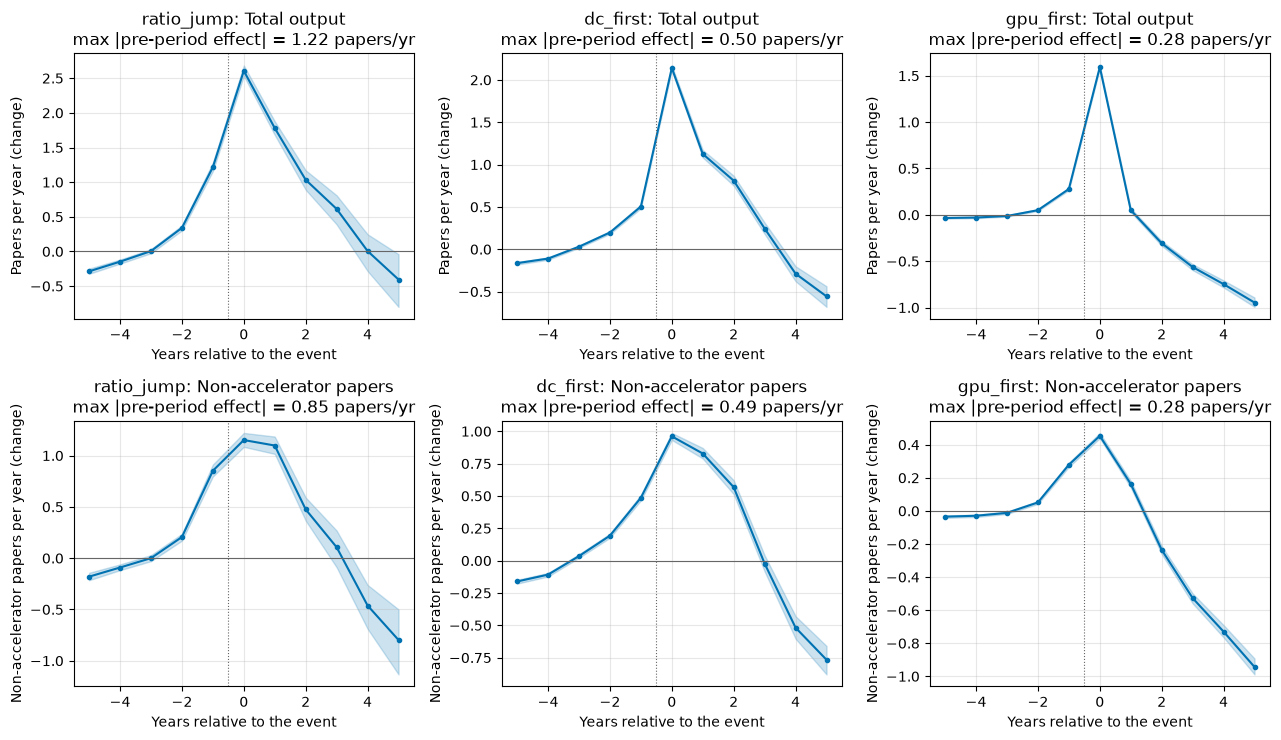

In [12]:
res_by_event = {et: run_event_study(event_type=et, outcomes=('n_papers', 'n_nonaccel'),
                                   variants=('riskset',))
                for et in au.EVENT_TYPES}
fig, axes = plt.subplots(2, len(au.EVENT_TYPES),
                         figsize=(4.3 * len(au.EVENT_TYPES), 7.5), squeeze=False)
for col, et in enumerate(au.EVENT_TYPES):
    for row, o in enumerate(('n_papers', 'n_nonaccel')):
        ax = axes[row][col]
        r = res_by_event[et][('riskset', o)]
        pre = r.filter(pl.col('tau') < 0)
        ax.fill_between(r['tau'], r['lo'], r['hi'], color=C_RISK, alpha=0.20)
        ax.plot(r['tau'], r['theta'], marker='o', ms=3, color=C_RISK)
        ax.axhline(0, color='#666666', lw=0.8)
        ax.axvline(-0.5, color='#666666', lw=0.8, ls=':')
        ax.set(xlabel='Years relative to the event', ylabel=ylab(o),
               title=f'{et}: {tlab(o)}\nmax |pre-period effect| = '
                     f'{pre["theta"].abs().max():.2f} papers/yr')
        ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Placebo: pseudo-jumps on authors who never jump

A placebo has to have a null expectation, and shifting real jumpers' event years
backwards does not: with a ±5 window a 6-year shift puts the placebo's
post-period (τ +1…+5) exactly on the real event's pre-period (τ −5…−1), so the
run-up to the real jump reappears as a placebo "effect". Worse, the shifted
baseline lands early in the career where `n_papers` is near zero, and
`log(1+n_papers)` turns ordinary career ramp-up into a huge log change (0 → 11
papers is 2.48 log points).

So the placebo draws GPU-ever authors with **no** jump and gives them pseudo-event
years sampled from the real event-year distribution. Treated and control units are
then the same population, differing only in a random date. `risk_events=pj` keeps
authors who really jumped out of the control pool.

The baseline output level is printed alongside θ, and each estimate is shown on
both scales — exact papers per year and `log(1 + papers)` — because a large θ on
the log means very little without knowing whether the baseline is four papers a
year or a fraction of one.

241,585 placebo events on never-jumping GPU-ever authors (vs 30,239 real ratio_jump events)
baseline mean n_papers  placebo 3.68  | real 4.33   -- theta on log(1+n_papers) is only interpretable relative to this
placebo/riskset: 241,537 of 241,585 matched, 1,206,738 pairs, 353,523 controls


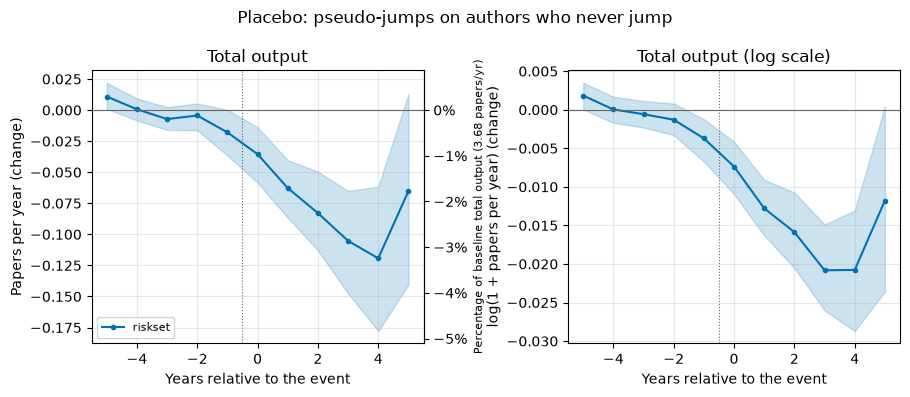

--- placebo n_papers ---
shape: (11, 5)
┌─────┬────────┬────────┬────────┬────────┐
│ tau ┆ theta  ┆ lo     ┆ hi     ┆ n      │
│ --- ┆ ---    ┆ ---    ┆ ---    ┆ ---    │
│ i64 ┆ f64    ┆ f64    ┆ f64    ┆ i64    │
╞═════╪════════╪════════╪════════╪════════╡
│ -5  ┆ 0.011  ┆ 0.001  ┆ 0.022  ┆ 241537 │
│ -4  ┆ 0.001  ┆ -0.008 ┆ 0.009  ┆ 241537 │
│ -3  ┆ -0.007 ┆ -0.016 ┆ 0.002  ┆ 241537 │
│ -2  ┆ -0.004 ┆ -0.016 ┆ 0.005  ┆ 241537 │
│ -1  ┆ -0.018 ┆ -0.037 ┆ 0.0    ┆ 241537 │
│ …   ┆ …      ┆ …      ┆ …      ┆ …      │
│ 1   ┆ -0.063 ┆ -0.087 ┆ -0.04  ┆ 203369 │
│ 2   ┆ -0.083 ┆ -0.113 ┆ -0.049 ┆ 139462 │
│ 3   ┆ -0.105 ┆ -0.148 ┆ -0.065 ┆ 85795  │
│ 4   ┆ -0.119 ┆ -0.178 ┆ -0.062 ┆ 46868  │
│ 5   ┆ -0.065 ┆ -0.141 ┆ 0.013  ┆ 23250  │
└─────┴────────┴────────┴────────┴────────┘
--- placebo log_papers ---
shape: (11, 5)
┌─────┬────────┬────────┬────────┬────────┐
│ tau ┆ theta  ┆ lo     ┆ hi     ┆ n      │
│ --- ┆ ---    ┆ ---    ┆ ---    ┆ ---    │
│ i64 ┆ f64    ┆ f64    ┆ f64    ┆ i64

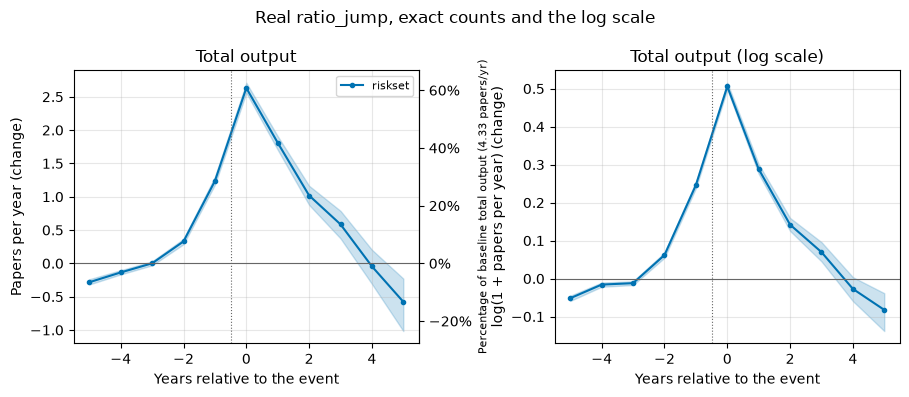

In [13]:
placebo = au.placebo_jumps(panel, jumps, event_type=EVENT_TYPE, seed=au.SEED)
print(f'{placebo.height:,} placebo events on never-jumping GPU-ever authors '
      f'(vs {pj.height:,} real {EVENT_TYPE} events)')
print(f'baseline mean n_papers  placebo {placebo["pre_papers_mean"].mean():.2f}  '
      f'| real {pj["pre_papers_mean"].mean():.2f}   '
      f'-- theta on log(1+n_papers) is only interpretable relative to this')

OUT_PAIR = ('n_papers', 'log_papers')      # exact count, and the log scale
ctrl_placebo = au.match_controls(panel, placebo, variant='riskset', seed=au.SEED,
                                 risk_events=pj)
print(f'placebo/riskset: {ctrl_placebo["authorid"].n_unique():,} of '
      f'{placebo.height:,} matched, {ctrl_placebo.height:,} pairs, '
      f'{ctrl_placebo["control_id"].n_unique():,} controls')
res_placebo = {('riskset', o): au.event_study(panel, placebo, ctrl_placebo, o)
               for o in OUT_PAIR}
res_placebo['_baseline'] = float(placebo['pre_papers_mean'].mean())
plot_event_study(res_placebo, outcomes=OUT_PAIR,
                 title='Placebo: pseudo-jumps on authors who never jump')
for o in OUT_PAIR:
    print(f'--- placebo {o} ---')
    print(res_placebo[('riskset', o)].sort('tau').with_columns(
        pl.col('theta').round(3), pl.col('lo').round(3), pl.col('hi').round(3)))

# The real estimate on the same two scales, so the comparison is like-for-like.
res_raw = run_event_study(outcomes=OUT_PAIR, variants=('riskset',))
plot_event_study(res_raw, outcomes=OUT_PAIR,
                 title=f'Real {EVENT_TYPE}, exact counts and the log scale')

## Coauthor decomposition

If the effect survives on jumps that were **not** coauthor-sourced, and on small
teams, then "a well-equipped collaborator joined" is not the whole story. If it
does not, that is the finding, and it should be reported as such.

ratio_jump/riskset: 16,037 of 18,378 jumpers matched, 80,173 pairs, 65,966 controls
ratio_jump/riskset: 9,881 of 11,861 jumpers matched, 49,392 pairs, 43,011 controls
ratio_jump/riskset: 3,276 of 3,750 jumpers matched, 16,377 pairs, 15,622 controls


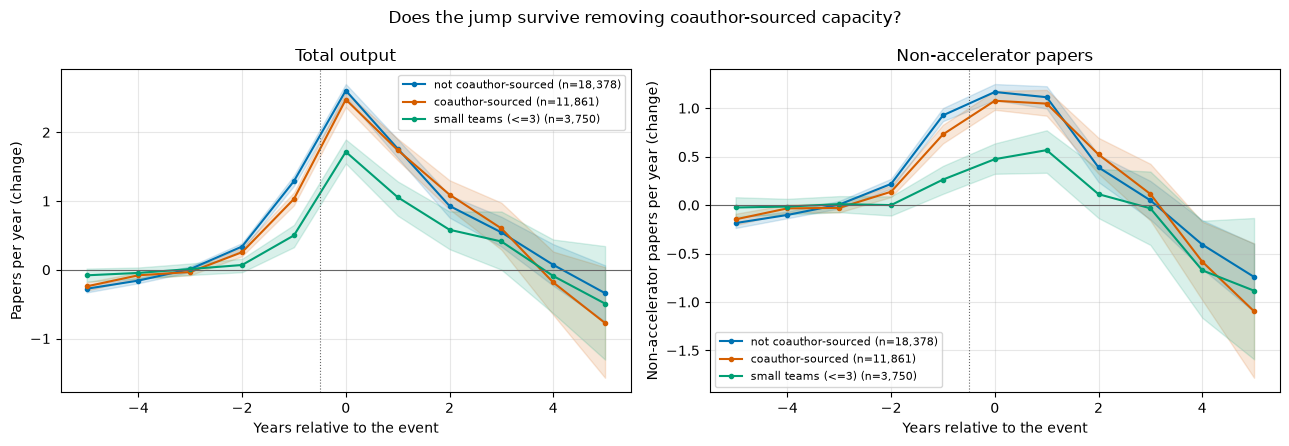

In [14]:
splits = {
    'not coauthor-sourced': pj.filter(~pl.col('coauthor_sourced')),
    'coauthor-sourced': pj.filter(pl.col('coauthor_sourced')),
    'small teams (<=3)': pj.filter(pl.col('min_team_size') <= 3),
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for (lab, jt), c in zip(splits.items(), [C_MED, C_FRONT, '#009E73']):
    if jt.height < 50:
        print(f'skipping {lab}: only {jt.height} events')
        continue
    r = run_event_study(jump_table=jt, outcomes=('n_papers', 'n_nonaccel'),
                        variants=('riskset',))
    for ax, o in zip(axes, ('n_papers', 'n_nonaccel')):
        d = r[('riskset', o)]
        ax.fill_between(d['tau'], d['lo'], d['hi'], color=c, alpha=0.15)
        ax.plot(d['tau'], d['theta'], marker='o', ms=3, color=c,
                label=f'{lab} (n={jt.height:,})')
for ax, o in zip(axes, ('n_papers', 'n_nonaccel')):
    ax.axhline(0, color='#666666', lw=0.8)
    ax.axvline(-0.5, color='#666666', lw=0.8, ls=':')
    ax.set(xlabel='Years relative to the event', ylabel=ylab(o), title=tlab(o))
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.suptitle('Does the jump survive removing coauthor-sourced capacity?')
plt.tight_layout(); plt.show()

## Citation outcomes

`i_3` needs three complete years, so the citation event study is restricted to
events at or before `CITATION_EVENT_CUTOFF`. Running it on later events would
report a mechanical decline in citations as an effect of GPU access.

2,042 of 30,239 ratio_jump events at or before 2019
ratio_jump/riskset: 1,770 of 2,042 jumpers matched, 8,850 pairs, 8,440 controls
ratio_jump/plus_never_gpu: 1,770 of 2,042 jumpers matched, 8,850 pairs, 8,505 controls


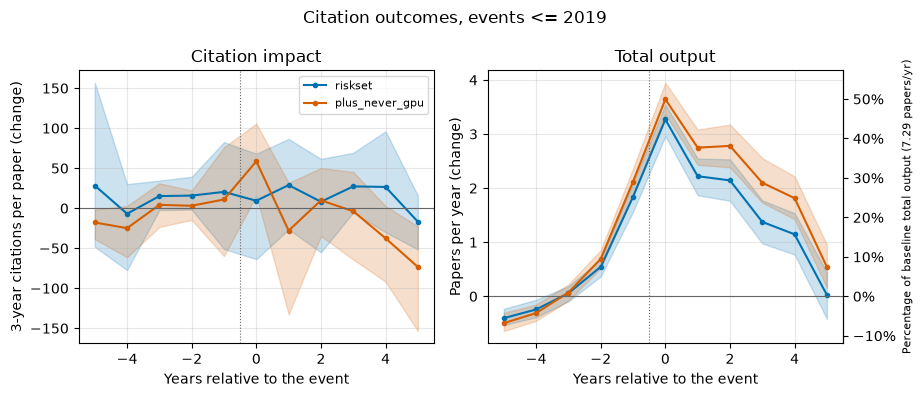

In [15]:
cj = pj.filter(pl.col('event_year') <= au.CITATION_EVENT_CUTOFF)
print(f'{cj.height:,} of {pj.height:,} {EVENT_TYPE} events at or before '
      f'{au.CITATION_EVENT_CUTOFF}')
res_cit = run_event_study(jump_table=cj, outcomes=('cit_i3_mean', 'n_papers'))
plot_event_study(res_cit, outcomes=('cit_i3_mean', 'n_papers'),
                 title=f'Citation outcomes, events <= {au.CITATION_EVENT_CUTOFF}')

## Calendar time and composition

Accelerator reporting rises steeply over the period, so it is worth being explicit
about what absorbs calendar time and what does not.

**What is already controlled.** `match_controls` assigns every control its
jumper's *own* event year, so a control at τ is in the same calendar year as its
jumper at τ, with the same baseline years. Calendar shocks common to a matched
cell are differenced out non-parametrically — stronger than an additive year
dummy, because it is fully interacted with the matching cell. The two-way FE
regression below writes the year effects down explicitly as a cross-check — and
turns out to be the *less* trustworthy of the two here: two-way FE degrades badly
under concentrated event timing, and it agrees with the matched difference to 0.23
on the balanced sample while diverging by 1.48 on the full one.

**What is not.** Two things survive that differencing:

1. **Jump *detection* is trend-contaminated.** A `ratio_jump` needs an observed
   FP32 increase, which needs a named model with a registry spec — and the share
   of accelerator-using papers naming a specific model rose 2.8% → 75.8% over the
   period (§4). Detection probability therefore rises with calendar time
   independently of any real capacity change. Controls cannot fix this: it is in
   the treatment definition, not the outcome.
2. **Composition across τ.** 93% of `ratio_jump` events are 2020 or later and only
   13% have a full +5 window, so τ=+1 is estimated on 2020–24 jumpers while τ=+5
   rests on a different, earlier cohort. The apparent decay across τ is confounded
   with that cohort switch. The balanced panel below is the fix.

A caveat that balancing does **not** fix: `author_year_panel` densifies only from
first to last publication, so an author who stops publishing has *no* rows
afterwards rather than zero-output rows. Exit is missing data, not measured zero,
which biases late-τ estimates upward in every variant here.

In [ ]:
# Balanced panel: the same authors at every tau
PANEL_HI = int(panel['year'].max())
e32 = pl.col('event_year').cast(pl.Int32)
y1 = panel.group_by('authorid').agg(pl.first('y1'))
n_censored = pj.filter(e32 + au.TAU_MAX > PANEL_HI).height
n_exit = (pj.filter(e32 + au.TAU_MAX <= PANEL_HI).join(y1, on='authorid', how='inner')
          .filter(pl.col('y1') < e32 + au.TAU_MAX).height)
bal = au.balanced_jumps(panel, pj)
print(f'{bal.height:,} of {pj.height:,} {EVENT_TYPE} events have a full '
      f'[{au.TAU_MIN}, +{au.TAU_MAX}] window')
print(f'  dropped, window runs past the panel ({PANEL_HI}): {n_censored:,}')
print(f'  dropped, author stopped publishing first:        {n_exit:,}'
      f'   <- survivorship, not censoring')

res_bal = run_event_study(jump_table=bal, outcomes=('n_papers', 'n_nonaccel'))
plot_event_study(res_bal, outcomes=('n_papers', 'n_nonaccel'),
                 title=f'Balanced panel: {EVENT_TYPE} events with a full window '
                       f'(n={bal.height:,})')
BAL_BASE = res_bal['_baseline']
for o in ('n_papers', 'n_nonaccel'):
    print(f'--- balanced {o} (risk-set controls) ---')
    print(au.as_share_of_baseline(res_bal[('riskset', o)].sort('tau'), BAL_BASE)
          .select('tau', 'theta', 'lo', 'hi', 'theta_pct', 'n')
          .with_columns(pl.selectors.float().round(2)))

In [ ]:
# Event-year cohorts: is the tau profile stable across calendar eras?
COHORTS = [(2010, 2017), (2018, 2020), (2021, 2022), (2023, 2025)]
C_COHORT = ['#0072B2', '#009E73', '#E69F00', '#D55E00']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for (a, b), c in zip(COHORTS, C_COHORT):
    jt = pj.filter(pl.col('event_year').is_between(a, b))
    if jt.height < 100:
        print(f'skipping {a}-{b}: only {jt.height} events')
        continue
    r = run_event_study(jump_table=jt, outcomes=('n_papers', 'n_nonaccel'),
                        variants=('riskset',))
    for ax, o in zip(axes, ('n_papers', 'n_nonaccel')):
        d = r[('riskset', o)].sort('tau')
        ax.fill_between(d['tau'], d['lo'], d['hi'], color=c, alpha=0.15)
        ax.plot(d['tau'], d['theta'], marker='o', ms=3, color=c,
                label=f'{a}-{b} (n={jt.height:,})')
for ax, o in zip(axes, ('n_papers', 'n_nonaccel')):
    ax.axhline(0, color='#666666', lw=0.8)
    ax.axvline(-0.5, color='#666666', lw=0.8, ls=':')
    ax.set(xlabel='Years relative to the event', ylabel=ylab(o), title=tlab(o))
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.suptitle('Event-year cohorts: later cohorts are truncated on the right')
plt.tight_layout(); plt.show()

In [ ]:
# Two-way fixed effects: unit AND calendar-year dummies, written down explicitly.
# Reference is the whole baseline window, so beta is directly comparable to theta.
ctrl_main = au.match_controls(panel, pj, variant='riskset', seed=au.SEED)
fe = {o: au.twoway_fe(panel, pj, ctrl_main, o) for o in ('n_papers', 'n_nonaccel')}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, o in zip(axes, ('n_papers', 'n_nonaccel')):
    f = fe[o].sort('tau')
    t = res_main[('riskset', o)].sort('tau')
    ax.fill_between(f['tau'], f['lo'], f['hi'], color=C_FRONT, alpha=0.18)
    ax.plot(f['tau'], f['beta'], marker='o', ms=4, color=C_FRONT,
            label='two-way FE (unit + calendar year)')
    ax.plot(t['tau'], t['theta'], marker='s', ms=3, ls='--', color=C_MED,
            label='matched difference (headline)')
    ax.axhline(0, color='#666666', lw=0.8)
    ax.axvline(-0.5, color='#666666', lw=0.8, ls=':')
    ax.set(xlabel='Years relative to the event', ylabel=ylab(o), title=tlab(o))
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.suptitle('Explicit year fixed effects vs the within-event-year matched difference')
plt.tight_layout(); plt.show()

for o in ('n_papers', 'n_nonaccel'):
    j = (fe[o].join(res_main[('riskset', o)].select('tau', 'theta'), on='tau',
                    how='inner').sort('tau')
         .with_columns(gap=(pl.col('beta') - pl.col('theta')).abs()))
    print(f'--- {o}: two-way FE vs matched difference ---')
    print(j.select('tau', 'beta', 'se', 'theta', 'gap', 'n_units')
           .with_columns(pl.selectors.float().round(3)))
    print(f'  max |beta - theta| = {j["gap"].max():.3f}  '
          f'(agreement means the matched cells absorb calendar time)')

# Two-way FE is fragile under concentrated event timing, and 93% of these events
# are 2020+, which makes calendar year and event time nearly collinear. Re-run it
# on the balanced sample (events 2010-2020, timing spread out): if beta and theta
# agree there and only diverge on the full sample, the divergence is the FE
# estimator's problem, not the matched design's.
fe_bal = au.twoway_fe(panel, bal, au.match_controls(panel, bal, seed=au.SEED),
                      'n_papers')
gap_full = (fe['n_papers'].join(res_main[('riskset', 'n_papers')].select('tau', 'theta'),
                                on='tau')
            .select((pl.col('beta') - pl.col('theta')).abs().max()).item())
gap_bal = (fe_bal.join(res_bal[('riskset', 'n_papers')].select('tau', 'theta'), on='tau')
           .select((pl.col('beta') - pl.col('theta')).abs().max()).item())
print(f'n_papers: max |beta - theta| = {gap_full:.2f} on the full sample, '
      f'{gap_bal:.2f} on the balanced one')
print('  -> they agree once timing is spread out, so the full-sample gap is the '
      'known two-way-FE\n     bias under concentrated timing, not a failure of '
      'the matched difference')

## Robustness

1. **Jump threshold** J in {2, 4, 8} — recomputed from the panel, so no rerun of
   stage 4b is needed.
2. **Count policy** floor1 vs explicit — Jaccard overlap of the jumper sets plus
   an overlay of theta.
3. **Access stock definition** — running max vs a 3-year window.

ratio_jump/riskset: 41,692 of 49,372 jumpers matched, 208,422 pairs, 131,032 controls
ratio_jump/riskset: 25,917 of 30,239 jumpers matched, 129,564 pairs, 94,160 controls
ratio_jump/riskset: 14,345 of 16,638 jumpers matched, 71,718 pairs, 59,413 controls


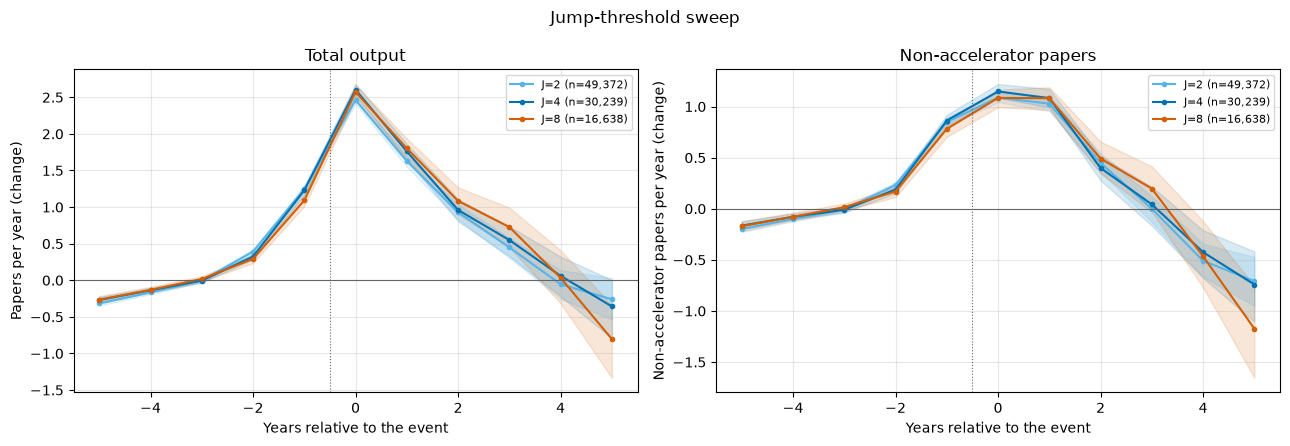

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for J, c in zip((2.0, 4.0, 8.0), [C_P90, C_MED, C_FRONT]):
    jt = au.find_jumps(gpu, jump_ratio=J).filter(pl.col('event_type') == 'ratio_jump')
    r = run_event_study(jump_table=jt, outcomes=('n_papers', 'n_nonaccel'),
                        variants=('riskset',))
    for ax, o in zip(axes, ('n_papers', 'n_nonaccel')):
        d = r[('riskset', o)]
        ax.fill_between(d['tau'], d['lo'], d['hi'], color=c, alpha=0.15)
        ax.plot(d['tau'], d['theta'], marker='o', ms=3, color=c,
                label=f'J={J:g} (n={jt.height:,})')
for ax, o in zip(axes, ('n_papers', 'n_nonaccel')):
    ax.axhline(0, color='#666666', lw=0.8)
    ax.axvline(-0.5, color='#666666', lw=0.8, ls=':')
    ax.set(xlabel='Years relative to the event', ylabel=ylab(o), title=tlab(o))
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.suptitle('Jump-threshold sweep')
plt.tight_layout(); plt.show()

jumper-set Jaccard floor1 vs explicit: 0.850 (30,239 vs 28,527)
same event year for 98.4% of the 27,006 authors in both
ratio_jump/riskset: 23,584 of 28,527 jumpers matched, 117,901 pairs, 87,103 controls


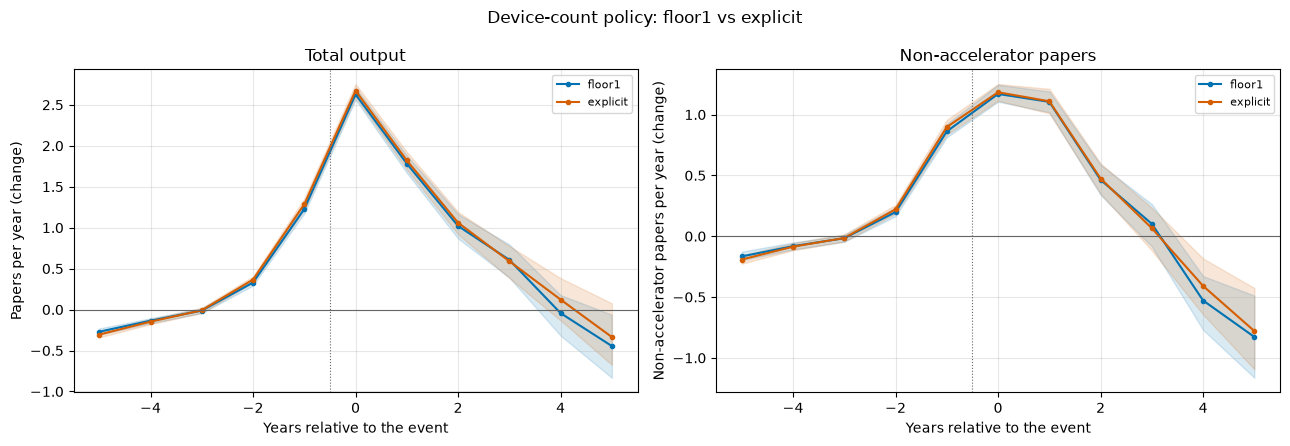

In [17]:
# floor1 vs explicit: do the two device-count policies pick the same jumpers?
try:
    alt_panel = au.add_outcomes(load('author_year', 'explicit').filter(
        pl.col('year').is_between(YEAR_MIN, YEAR_MAX)))
    alt_jumps = load('author_jumps', 'explicit').filter(
        pl.col('event_type') == EVENT_TYPE)
except Exception as e:                       # the explicit variant may not be built
    print(f'explicit panel unavailable: {e}')
    alt_panel = alt_jumps = None

if alt_jumps is not None:
    a, b = set(pj['authorid']), set(alt_jumps['authorid'])
    print(f'jumper-set Jaccard floor1 vs explicit: {len(a & b) / len(a | b):.3f} '
          f'({len(a):,} vs {len(b):,})')
    same = (pj.select('authorid', 'event_year')
            .join(alt_jumps.select('authorid', alt_year='event_year'),
                  on='authorid', how='inner'))
    print(f'same event year for {100 * (same["event_year"] == same["alt_year"]).mean():.1f}% '
          f'of the {same.height:,} authors in both')
    r_alt = run_event_study(jump_table=alt_jumps, panel_df=alt_panel,
                            outcomes=('n_papers', 'n_nonaccel'),
                            variants=('riskset',))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, o in zip(axes, ('n_papers', 'n_nonaccel')):
        for lab, r, c in (('floor1', res_main, C_MED), ('explicit', r_alt, C_FRONT)):
            d = r[('riskset', o)]
            ax.fill_between(d['tau'], d['lo'], d['hi'], color=c, alpha=0.15)
            ax.plot(d['tau'], d['theta'], marker='o', ms=3, color=c, label=lab)
        ax.axhline(0, color='#666666', lw=0.8)
        ax.axvline(-0.5, color='#666666', lw=0.8, ls=':')
        ax.set(xlabel='Years relative to the event', ylabel=ylab(o), title=tlab(o))
        ax.legend(fontsize=8); ax.grid(alpha=0.3)
    fig.suptitle('Device-count policy: floor1 vs explicit')
    plt.tight_layout(); plt.show()

3-year-window stock yields 26,764 ratio_jumps vs 30,239 under the running max
ratio_jump/riskset: 22,443 of 26,764 jumpers matched, 112,201 pairs, 83,645 controls


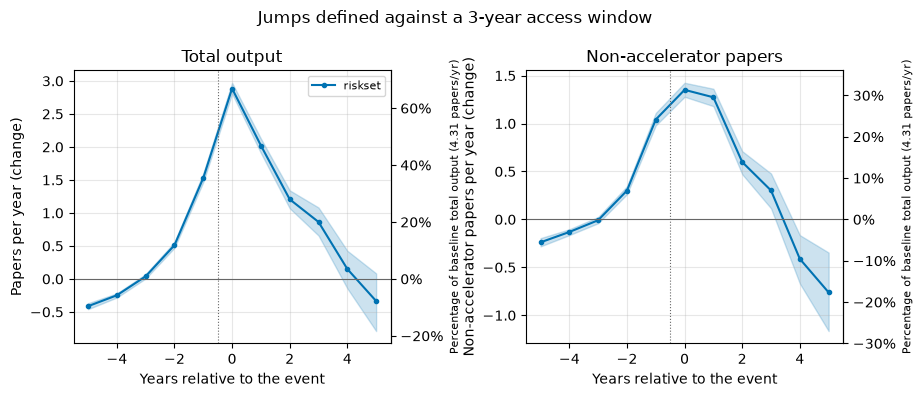

In [18]:
# Access stock: running max (primary) vs a 3-year window
w3 = gpu.with_columns(access_fp32_stock=pl.col('access_fp32_stock_w3'))
jt = au.find_jumps(w3, jump_ratio=au.JUMP_RATIO).filter(
    pl.col('event_type') == 'ratio_jump')
print(f'3-year-window stock yields {jt.height:,} ratio_jumps vs '
      f'{pj.height:,} under the running max')
r = run_event_study(jump_table=jt, outcomes=('n_papers', 'n_nonaccel'),
                    variants=('riskset',))
plot_event_study(r, outcomes=('n_papers', 'n_nonaccel'),
                 title='Jumps defined against a 3-year access window')

## Standing caveats for the paper

- **Not causal.** Access is chosen. The design controls for *timing* among
  accelerator-using peers; it cannot control for the project that motivated the
  purchase. Anticipation inflates theta and leaves no pre-trend signature.
- **tau=0 is mechanical.** The jump is itself a paper.
- **Author-id error is not symmetric.** Splits truncate careers and attenuate
  post-jump effects; merges inflate output and can fabricate jumps.
- **The never-GPU control arm is an upper bound**, not an estimate.
- **Access is what was *reported*, nameplate peak, not utilized FLOPs** — the same
  caveat as every §5 capacity figure, inherited here.
- **The never-GPU pool is hash-bounded** (see `authorship.hash_pool`): a
  deterministic id subsample, so it is reproducible but not the full universe of
  non-users. Strata short of the 5x target are printed by `--step panel`.
- **Coauthor access is exact for accelerator papers only** — a coauthor whose
  capacity never appeared in a full-text accelerator paper reads as no access.
